# Part D - Development of Three Base Models

**Task:** Predict loan status (`0 = Fully Paid`, `1 = Charged Off`) using the processed data from Part C.

Models: Logistic Regression, Random Forest and Histogram Gradient Boosting. All models use the same training and validation data, balanced class weights and a 0.50 threshold. The test set is reserved for Part G.

## 1. Load datasets

Use the existing Part C exports. No additional preprocessing or splitting is performed.

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)

from google.colab import drive
drive.mount('/content/drive')

# Use the folder containing the Part C exports.
ROOT = Path('/content/drive/MyDrive/ML_Group')
if not (ROOT / 'train_dataset.csv').exists():
    ROOT = Path('/content/drive/MyDrive/ML_Group_Assignment')

train_df = pd.read_csv(ROOT / 'train_dataset.csv')
val_df = pd.read_csv(ROOT / 'validation_dataset.csv')

assert train_df.columns.equals(val_df.columns)
features = train_df.columns.drop('target')
X_train, y_train = train_df[features], train_df['target']
X_val, y_val = val_df[features], val_df['target']

print('Folder:', ROOT)
print('Train:', X_train.shape, '| Validation:', X_val.shape)
print('Training target distribution:')
print(y_train.value_counts().sort_index())

Mounted at /content/drive
Folder: /content/drive/MyDrive/ML_Group
Train: (198221, 66) | Validation: (45302, 66)
Training target distribution:
target
0    167448
1     30773
Name: count, dtype: int64


## 2. Evaluation setup

Balanced weights address the class imbalance. Accuracy, precision, recall, F1 and ROC-AUC meet the evaluation requirements; F2 and average precision provide additional context.

In [3]:
# Calculate weights from training labels only.
classes = np.array([0, 1])
weights = compute_class_weight('balanced', classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))
weight_ratio = class_weights[1] / class_weights[0]

print(f"Fully Paid class weight: {class_weights[0]:.4f}")
print(f"Charged Off class weight: {class_weights[1]:.4f}")
print(f"Charged Off gets {weight_ratio:.2f} times the weight of Fully Paid.")

results = []
predictions = pd.DataFrame({'actual': y_val.to_numpy()})
models = {}

# Use the same evaluation method for all models.
def evaluate(name, model):
    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start

    prob = model.predict_proba(X_val)[:, 1]
    pred = (prob >= 0.50).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()

    result = {
        'Model': name,
        'Accuracy': accuracy_score(y_val, pred),
        'Precision': precision_score(y_val, pred, zero_division=0),
        'Recall': recall_score(y_val, pred, zero_division=0),
        'F1-score': f1_score(y_val, pred, zero_division=0),
        'F2-score': fbeta_score(y_val, pred, beta=2, zero_division=0),
        'ROC-AUC': roc_auc_score(y_val, prob),
        'Average Precision': average_precision_score(y_val, prob),
        'Training Time (s)': train_time,
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    }
    results.append(result)
    predictions[f'{name}_prob'] = prob
    predictions[f'{name}_pred'] = pred
    models[name] = model

    print(pd.Series(result).to_string())
    print('Confusion matrix:', confusion_matrix(y_val, pred))
    print(classification_report(y_val, pred, target_names=['Fully Paid', 'Charged Off'], zero_division=0))

Fully Paid class weight: 0.5919
Charged Off class weight: 3.2207
Charged Off gets 5.44 times the weight of Fully Paid.


## 3. Logistic Regression

A regularised linear model is used as an interpretable baseline. It is relatively efficient on large datasets, but may miss nonlinear relationships. Training cost depends on the solver, number of features and iterations. Standardised features from Part C are suitable for this model.

In [ ]:
# Baseline linear classifier.
lr_model = LogisticRegression(
    C=1.0, solver='lbfgs', max_iter=1000,
    class_weight=class_weights, random_state=42
)
evaluate('Logistic Regression', lr_model)

Model                Logistic Regression
Accuracy                        0.633526
Precision                       0.245869
Recall                          0.657525
F1-score                        0.357905
F2-score                         0.49258
ROC-AUC                         0.694502
Average Precision               0.281911
Training Time (s)               6.165489
TN                                 24073
FP                                 14192
FN                                  2410
TP                                  4627
Confusion matrix: [[24073 14192]
 [ 2410  4627]]
              precision    recall  f1-score   support

  Fully Paid       0.91      0.63      0.74     38265
 Charged Off       0.25      0.66      0.36      7037

    accuracy                           0.63     45302
   macro avg       0.58      0.64      0.55     45302
weighted avg       0.81      0.63      0.68     45302



## 4. Random Forest

Random Forest combines multiple decision trees and can capture nonlinear patterns and feature interactions. It is less interpretable than Logistic Regression and can require more memory and training time. Training cost increases with the number and size of trees. It is suitable for the mixed borrower and loan features encoded in Part C.

In [ ]:
# Baseline bagging model.
rf_model = RandomForestClassifier(
    n_estimators=100, class_weight=class_weights,
    random_state=42, n_jobs=-1
)
evaluate('Random Forest', rf_model)

Model                Random Forest
Accuracy                  0.844334
Precision                 0.380952
Recall                    0.003411
F1-score                  0.006761
F2-score                  0.004254
ROC-AUC                   0.675324
Average Precision         0.260722
Training Time (s)        97.017607
TN                           38226
FP                              39
FN                            7013
TP                              24
Confusion matrix: [[38226    39]
 [ 7013    24]]
              precision    recall  f1-score   support

  Fully Paid       0.84      1.00      0.92     38265
 Charged Off       0.38      0.00      0.01      7037

    accuracy                           0.84     45302
   macro avg       0.61      0.50      0.46     45302
weighted avg       0.77      0.84      0.77     45302



## 5. Histogram Gradient Boosting

Histogram Gradient Boosting builds trees sequentially and uses feature binning for efficient training. It can model nonlinear relationships, but requires careful tuning and is less transparent than a linear model. Training cost depends on iterations, tree complexity and feature binning. It is suitable for this large tabular dataset.

In [ ]:
# Baseline boosting model.
hgb_model = HistGradientBoostingClassifier(
    max_iter=100, learning_rate=0.1, max_leaf_nodes=31,
    class_weight=class_weights, random_state=42
)
evaluate('Histogram Gradient Boosting', hgb_model)

Model                Histogram Gradient Boosting
Accuracy                                0.633879
Precision                               0.246024
Recall                                   0.65724
F1-score                                0.358028
F2-score                                0.492577
ROC-AUC                                 0.697207
Average Precision                       0.284048
Training Time (s)                      11.883229
TN                                         24091
FP                                         14174
FN                                          2412
TP                                          4625
Confusion matrix: [[24091 14174]
 [ 2412  4625]]
              precision    recall  f1-score   support

  Fully Paid       0.91      0.63      0.74     38265
 Charged Off       0.25      0.66      0.36      7037

    accuracy                           0.63     45302
   macro avg       0.58      0.64      0.55     45302
weighted avg       0.81      0.63      0.6

## 6. Baseline comparison

Compare performance on the same validation set. Accuracy alone may be misleading because Fully Paid is the majority class.

,Accuracy,Precision,Recall,F1-score,F2-score,ROC-AUC,Average Precision,Training Time (s)
Model,,,,,,,,
Logistic Regression,0.6335,0.2459,0.6575,0.3579,0.4926,0.6945,0.2819,6.1655
Random Forest,0.8443,0.3810,0.0034,0.0068,0.0043,0.6753,0.2607,97.0176
Histogram Gradient Boosting,0.6339,0.2460,0.6572,0.3580,0.4926,0.6972,0.2840,11.8832


Majority-class accuracy: 0.8447


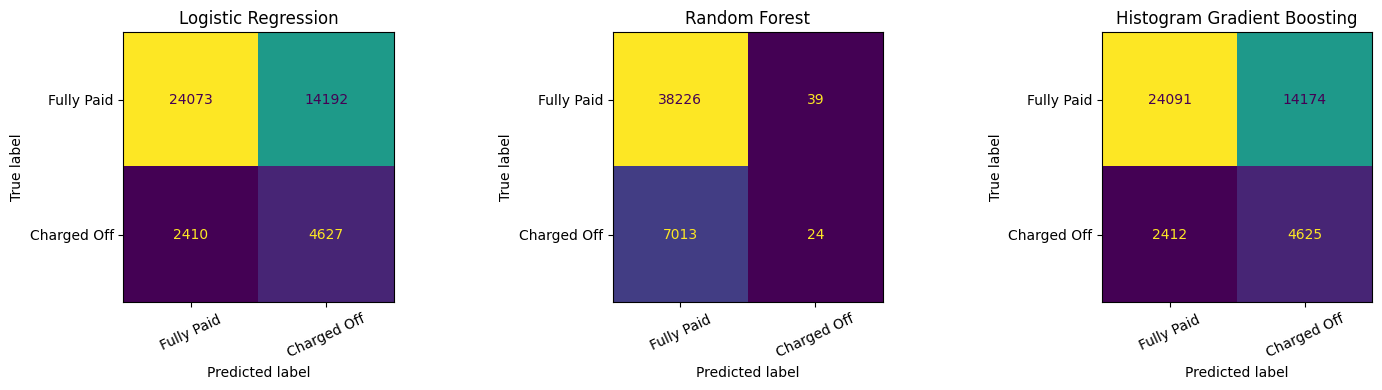

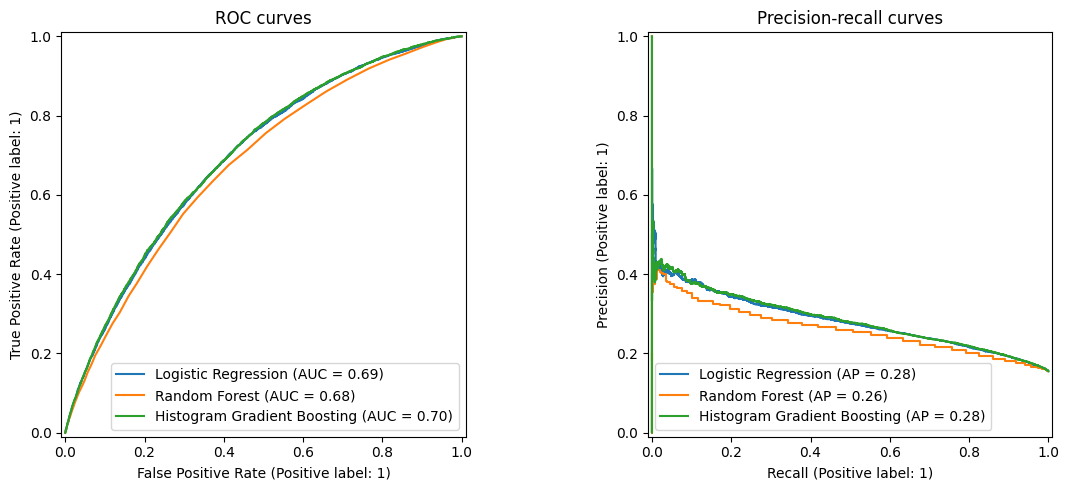

In [ ]:
# Compare all three models.
comparison = pd.DataFrame(results).set_index('Model')
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'F2-score',
           'ROC-AUC', 'Average Precision', 'Training Time (s)']
display(comparison[metrics].round(4))
print('Majority-class accuracy:', round((y_val == 0).mean(), 4))

# Display confusion matrices.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_val, predictions[f'{name}_pred'], labels=[0, 1],
        display_labels=['Fully Paid', 'Charged Off'],
        ax=ax, colorbar=False, values_format='d'
    )
    ax.set_title(name)
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

# Compare probability-based performance.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name in models:
    prob = predictions[f'{name}_prob']
    RocCurveDisplay.from_predictions(y_val, prob, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_val, prob, name=name, ax=axes[1])
axes[0].set_title('ROC curves')
axes[1].set_title('Precision-recall curves')
plt.tight_layout()
plt.show()

## 7. Save baseline results

Save the comparison and validation predictions for Parts E–G. Models can be retrained using the configurations above.

In [ ]:
# Save results without saving large model files.
output = ROOT / 'Part_D_Results'
output.mkdir(exist_ok=True)
comparison.reset_index().to_csv(output / 'baseline_metrics.csv', index=False)
predictions.to_csv(output / 'baseline_validation_predictions.csv', index=False)
print('Saved to:', output)

Saved to: /content/drive/MyDrive/ML_Group/Part_D_Results


## 8. Discussion

- **Logistic Regression:** Simple and interpretable, with strong charge-off recall but many false positives.
- **Random Forest:** High accuracy but very low recall at the 0.50 threshold. Its ROC-AUC suggests that threshold selection may be worth investigating.
- **Histogram Gradient Boosting:** Similar recall to Logistic Regression, with slightly higher ROC-AUC and average precision in the initial experiment.

The comparison is based on validation performance, not the untouched test set. Part E will investigate hyperparameters and classification thresholds before selecting models for the ensemble.